# Random seed

In [1]:
import os
import random
import numpy as np

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Для будущей реализации FM на PyTorch
try:
    import torch

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

except ImportError:
    pass

# Датасет

Датасет **KuaiRec** — это открытый набор реальных данных, собранных из логов китайской платформы для обмена короткими видео Kuaishou. Он содержит информацию о взаимодействиях пользователей с видео, а также дополнительные характеристики пользователей и объектов.

Основу датасета составляют две таблицы взаимодействий — *small_matrix.csv* и *big_matrix.csv* - это матрицы с различной степенью заполненности.


*   **small_matrix** содержит 4 676 570 взаимодействий 1 411 пользователей с 3327 видео, заполненность *99,6%*

*   **big_matrix** содержит 12 530 806 взаимодействий 7 176 пользователей с 10 728 видео при заполненности около *16,3%*

Каждая запись описывает взаимодействие пользователя с определённым видео. Для каждой пары пользователя и видео доступны идентификаторы `user_id` и `video_id`, длительность просмотра `play_duration`, длительность видео `video_duration` и временная метка взаимодействия `timestamp`. На основе этих данных рассчитывается показатель **`watch_ratio`**, представляющий собой отношение времени просмотра к продолжительности видео. Он используется в качестве количественного сигнала предпочтения: более высокие значения могут свидетельствовать о большем интересе пользователя к контенту, хотя этот показатель не является прямой оценкой удовлетворенности.

Помимо пользовательских взаимодействий, в датасете представлены дополнительные признаки. Файл user_features.csv содержит характеристики пользователей, item_categories.csv — категории видео, а item_daily_features.csv — ежедневную статистику и характеристики объектов. Файл social_network.csv описывает связи между пользователями. Эти сведения позволяют использовать не только историю взаимодействий, но и метапризнаки пользователей и видео, что особенно важно для построения факторизационной машины (FM).

В данной работе KuaiRec используется для решения задачи персонализированного ранжирования видео. Для каждого пользователя необходимо сформировать top-10 видео, которые предположительно будут ему наиболее интересны. Качество рекомендаций оценивается на отложенных взаимодействиях, которые не использовались при обучении моделей. Поскольку датасет содержит временные метки, для разделения данных на обучающую, валидационную и тестовую выборки используется временной принцип. Для обеспечения воспроизводимости фиксируется random_seed.

**Источник данных:** [KuaiRec — официальный репозиторий GitHub](https://github.com/chongminggao/KuaiRec), [страница проекта](https://kuairec.com/).

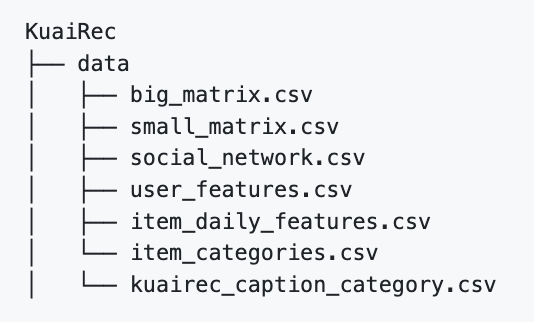

Авторы пишут:  

> *"We provide some basic statistics of the KuaiRec dataset. The description of this dataset can be referred to https://chongminggao.github.io/KuaiRec/"*

Поэтому возьмем часть реализованной ими аналитики

## EDA based on [Statistics of KuaiRec](https://kuairec.com/Statistics_KuaiRec.html)

### Load data

If you are using Google Colab, make sure you have added shortcut of this [shared link](https://drive.google.com/drive/folders/1bAm07YnKRKB6SVHB8Mqz6v6W8ppLaJwB) to your own Google Drive. Then, you should load it from your space by indicating the correct path as follows.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

rootpath="./drive/MyDrive/data"

Mounted at /content/drive


In [3]:
import pandas as pd

print("Loading big matrix...")
big_matrix = pd.read_csv(rootpath + "/big_matrix.csv")
print("Loading small matrix...")
small_matrix = pd.read_csv(rootpath + "/small_matrix.csv")

print("Loading social network...")
social_network = pd.read_csv(rootpath + "/social_network.csv")
social_network["friend_list"] = social_network["friend_list"].map(eval)

print("Loading item features...")
item_categories = pd.read_csv(rootpath + "/item_categories.csv")
item_categories["feat"] = item_categories["feat"].map(eval)

print("Loading user features...")
user_features = pd.read_csv(rootpath + "/user_features.csv")

print("Loading items' daily features...")
item_daily_features = pd.read_csv(rootpath + "/item_daily_features.csv")

print("All data loaded.")

Loading big matrix...
Loading small matrix...
Loading social network...
Loading item features...
Loading user features...
Loading items' daily features...
All data loaded.


### Visualization of the four tables

In [4]:
big_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,0,3649,13838,10867,2020-07-05 00:08:23.438,20200705,1.593879e+09,1.273397
1,0,9598,13665,10984,2020-07-05 00:13:41.297,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,2020-07-05 00:16:06.687,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,2020-07-05 00:20:26.792,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,2020-07-05 00:43:05.128,20200705,1.593881e+09,0.078000
...,...,...,...,...,...,...,...,...
12530801,7175,1281,34618,140017,2020-09-05 15:07:10.576,20200905,1.599290e+09,0.247241
12530802,7175,3407,12619,21888,2020-09-05 15:08:45.228,20200905,1.599290e+09,0.576526
12530803,7175,10360,2407,7067,2020-09-05 19:10:29.041,20200905,1.599304e+09,0.340597
12530804,7175,10360,6455,7067,2020-09-05 19:10:36.995,20200905,1.599304e+09,0.913400


In [16]:
print(f'''{int(big_matrix['timestamp'].isna().sum())/len(big_matrix):.4f} взаимодействий без временных меток ({int(big_matrix['timestamp'].isna().sum())}/{len(big_matrix)})''')

0.0000 взаимодействий без временных меток (0/12530806)


In [7]:
small_matrix

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364
...,...,...,...,...,...,...,...,...
4676565,7162,2267,11908,5467,NaN,NaN,NaN,2.178160
4676566,7162,2065,11919,6067,NaN,NaN,NaN,1.964562
4676567,7162,1296,16690,19870,NaN,NaN,NaN,0.839960
4676568,7162,4822,11862,24400,NaN,NaN,NaN,0.486148


In [33]:
small_matrix.isna().sum() / len(small_matrix) # получилось 0.0389 взаимодействий без временных меток (181992/4676570)

,0
user_id,0.000000
video_id,0.000000
play_duration,0.000000
video_duration,0.000000
time,0.038916
date,0.038916
timestamp,0.038916
watch_ratio,0.000000


In [34]:
print(f'''число уникальных взаимодействий по паре юзер-айтем {len(small_matrix.groupby(['user_id', 'video_id']).size())} (все уникальные)''')

число уникальных взаимодействий по паре юзер-айтем 4676570 (все уникальные)


In [30]:
import numpy as np
import pandas as pd

# 1. Убираем строки без timestamp
df = small_matrix.copy()
df = df.dropna(
    subset=["timestamp", "user_id", "video_id", "watch_ratio"]
)

# 2. Воспроизводимая подвыборка:
# 1100 пользователей × 1800 видео = максимум 1,96 млн пар
np.random.seed(SEED)
selected_users = np.random.choice(df["user_id"].unique(), 1100, replace=False)
selected_items = np.random.choice(df["video_id"].unique(), 1800, replace=False)

df = df[
    df["user_id"].isin(selected_users)
    & df["video_id"].isin(selected_items)
]

# 3. Делим по времени: 70% / 15% / 15%
t1, t2 = df["timestamp"].quantile([0.70, 0.85])

train_df = df[df["timestamp"] <= t1].copy()

val_df = df[(df["timestamp"] > t1) & (df["timestamp"] <= t2)].copy()

test_df = df[df["timestamp"] > t2].copy()


# 4. Оставляем пользователей и видео, представленные в train.
users = train_df["user_id"].unique()
items = train_df["video_id"].unique()

val_df = val_df[
    val_df["user_id"].isin(users)
    & val_df["video_id"].isin(items)
].copy()

test_df = test_df[
    test_df["user_id"].isin(users)
    & test_df["video_id"].isin(items)
].copy()

print("Пользователей:", len(users))
print("Видео:", len(items))
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Пользователей: 1100
Видео: 1437
Train: 1325804
Validation: 138636
Test: 46904


In [36]:
1325804 / (1100 * 1437)

0.8387448598722085

In [22]:
item_categories_selected = item_categories[item_categories['video_id'].isin(items)].copy()
item_categories_selected

,video_id,feat
103,103,[12]
109,109,"[18, 5]"
120,120,[9]
130,130,"[15, 20]"
131,131,"[9, 28]"
...,...,...
10259,10259,[16]
10271,10271,[26]
10278,10278,[28]
10279,10279,[26]


In [23]:
social_network_selected = social_network[social_network['user_id'].isin(users)].copy()
social_network_selected

,user_id,friend_list
1,24,[2665]
2,4402,[38]
4,7087,[7117]
13,1796,[2876]
15,6745,[2278]
...,...,...
447,2059,"[3903, 5079]"
449,5547,[3354]
463,2024,"[3936, 2415, 2196]"
465,6802,"[2729, 6306]"


In [31]:
item_daily_features

,video_id,date,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,video_width,video_height,...,download_cnt,download_user_num,report_cnt,report_user_num,reduce_similar_cnt,reduce_similar_user_num,collect_cnt,collect_user_num,cancel_collect_cnt,cancel_collect_user_num
0,0,20200705,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,8,8,0,0,3,3,NaN,NaN,NaN,NaN
1,0,20200706,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,5,5,NaN,NaN,NaN,NaN
2,0,20200707,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,0,0,0,0,NaN,NaN,NaN,NaN
3,0,20200708,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,3,3,0,0,3,3,NaN,NaN,NaN,NaN
4,0,20200709,3309,NORMAL,2020-03-30,ShortImport,public,5966.0,720,1280,...,2,2,2,1,1,1,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
343336,10723,20200905,236,NORMAL,2020-09-05,ShortImport,public,4833.0,720,1280,...,0,0,0,0,0,0,0.0,0.0,0.0,0.0
343337,10724,20200905,5271,NORMAL,2020-09-05,LongImport,public,54720.0,720,1280,...,1,1,0,0,0,0,0.0,0.0,0.0,0.0
343338,10725,20200905,1924,NORMAL,2020-09-05,ShortImport,public,15800.0,576,1024,...,5,5,0,0,4,4,0.0,0.0,0.0,0.0
343339,10726,20200905,7604,NORMAL,2020-09-05,ShortImport,public,5132.0,528,960,...,2,2,0,0,1,1,0.0,0.0,0.0,0.0


In [32]:
user_features

,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,...,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,high_active,0,0,0,5,"(0,10]",0,0,0,...,184,6,3,0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,full_active,0,0,0,386,"(250,500]",4,"[1,10)",2,...,186,6,2,0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,full_active,0,0,0,27,"(10,50]",0,0,0,...,51,2,3,0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,full_active,0,0,0,16,"(10,50]",0,0,0,...,251,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,full_active,0,0,0,122,"(100,150]",4,"[1,10)",0,...,99,4,2,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7171,7171,full_active,0,0,1,52,"(50,100]",1,"[1,10)",0,...,259,1,4,0,1.0,0.0,0.0,0.0,0.0,0.0
7172,7172,full_active,0,0,0,45,"(10,50]",2,"[1,10)",2,...,11,2,0,0,1.0,0.0,0.0,0.0,0.0,0.0
7173,7173,full_active,0,0,0,615,500+,3,"[1,10)",2,...,51,2,2,0,1.0,0.0,0.0,0.0,0.0,0.0
7174,7174,full_active,0,0,0,959,500+,0,0,0,...,107,3,2,0,0.0,0.0,0.0,0.0,0.0,0.0


### Codes for visualization

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
myfont = FontProperties(fname="./SimHei.ttf")

def visual_continue(df, func=None):
    ax = sns.distplot(df)
    if func:
        func(ax)

    gca = plt.gca()
    fig_title = "Statistics of {}".format(df.name)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Density", fontsize=14)
    gca.set_xlabel(df.name, fontsize=14)

    plt.show()

def visual_statistics_discrete(df, var="my_variable", display_ratio=True, func=None, order=None, size=(6, 4.5)):
    ncount = len(df)

    fig = plt.figure(figsize=size)
    ax1 = fig.add_axes([0.14, 0.15, 0.74, 0.75])
    sns.countplot(x=df, color="#9fc5e8", linewidth=.6, edgecolor='k', ax=ax1, order=order)


    plt.grid(axis='y', linestyle='-.')

    gca = plt.gca()
    fig_title = "Statistics of {}".format(var)
    gca.set_title(fig_title, fontsize=14)
    gca.set_ylabel("Count", fontsize=14)
    gca.set_xlabel(var, fontsize=14)

    if func:
        func(ax1)

    if display_ratio:
        # Make twin axis
        ax2 = ax1.twinx()
        ax2.set_ylabel("ratio (%)", fontsize=14)


        for p in ax1.patches:
            x = p.get_bbox().get_points()[:, 0]
            y = p.get_bbox().get_points()[1, 1]
            ax1.annotate('{:.1f}%'.format(100. * y / ncount), (x.mean(), y),
                         ha='center', va='bottom', fontsize=10, rotation=30)  # set the alignment of the text

        ax2.set_ylim(0, ax1.get_ylim()[1] / ncount * 100)

    plt.show()

In [20]:
import warnings; warnings.simplefilter('ignore')

### Statistics of social network

count    113.000000
mean       1.486726
std        0.945998
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        5.000000
Name: friend_list, dtype: float64


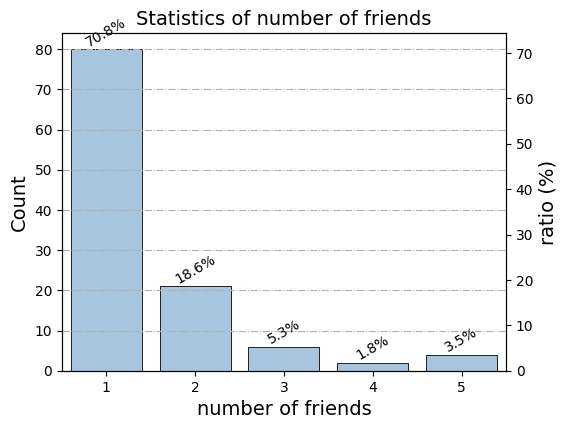

In [21]:
print(social_network_selected.friend_list.map(len).describe())
visual_statistics_discrete(social_network_selected.friend_list.map(len), "number of friends")

### Statistics of video features

count    10728.000000
mean         1.183166
std          0.436205
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: feat, dtype: float64


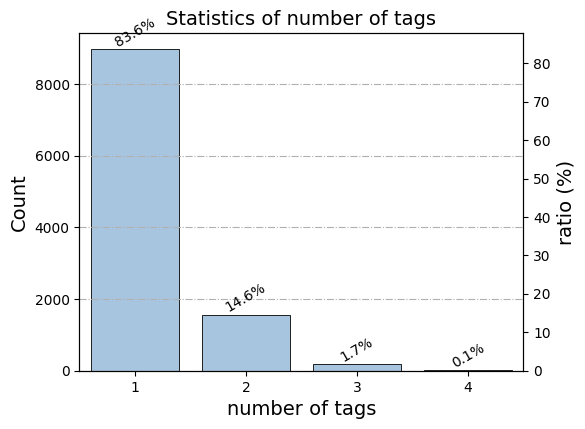

In [36]:
num_feat = item_categories.feat.map(len)
print(num_feat.describe())
visual_statistics_discrete(num_feat, "number of tags")

### Distribution of the 31 tags of items

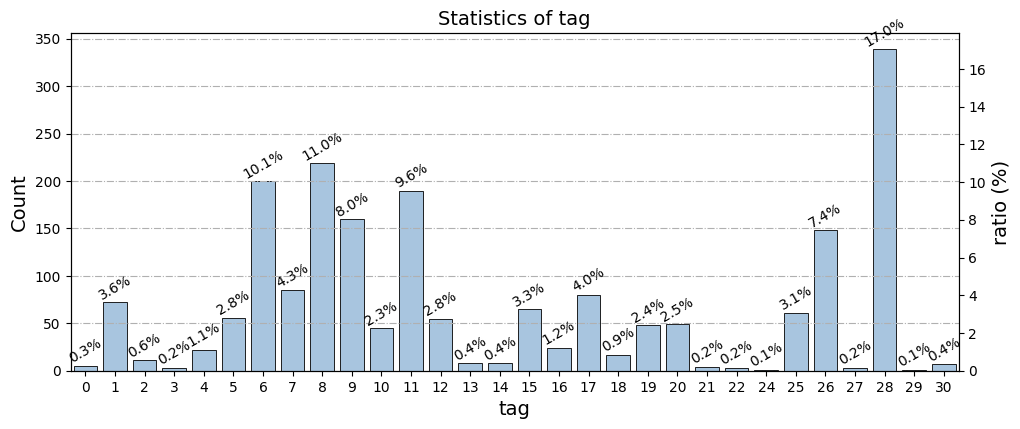

In [24]:
import collections
import itertools

cnt = item_categories_selected.feat.map(collections.Counter)
cnt_all = collections.Counter()
for d in cnt:
    cnt_all.update(d)
# print(dict(cnt_all))
all_feat = pd.Series(sorted(list(itertools.chain.from_iterable([[i]*k for i,k in cnt_all.items()]))),name="feat")
# print(all_feat)
visual_statistics_discrete(all_feat, "tag", size=(12,4.5))

### Distribution of watch_ratio in big matrix

count    1.241552e+07
mean     8.510664e-01
std      7.185296e-01
min      0.000000e+00
25%      3.111008e-01
50%      7.161066e-01
75%      1.161843e+00
max      5.000000e+00
Name: watch_ratio, dtype: float64


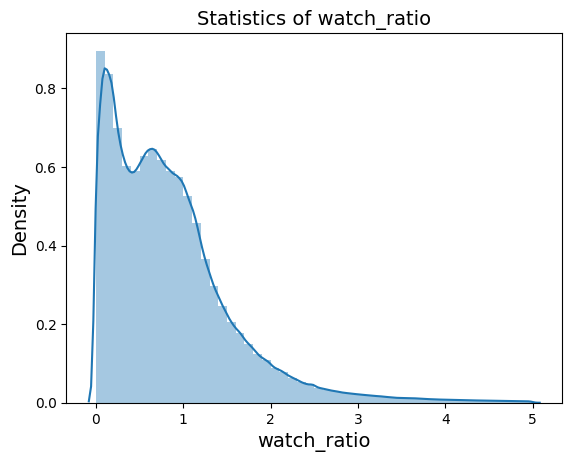

In [38]:
big_watch_ratio = big_matrix.watch_ratio[big_matrix.watch_ratio <= 5]
print(big_watch_ratio.describe())
visual_continue(big_watch_ratio)

### Distribution of watch_ratio in small matrix (in selected subsample)

count    1.884681e+06
mean     8.554661e-01
std      5.901807e-01
min      0.000000e+00
25%      4.702264e-01
50%      7.682505e-01
75%      1.113892e+00
max      5.000000e+00
Name: watch_ratio, dtype: float64


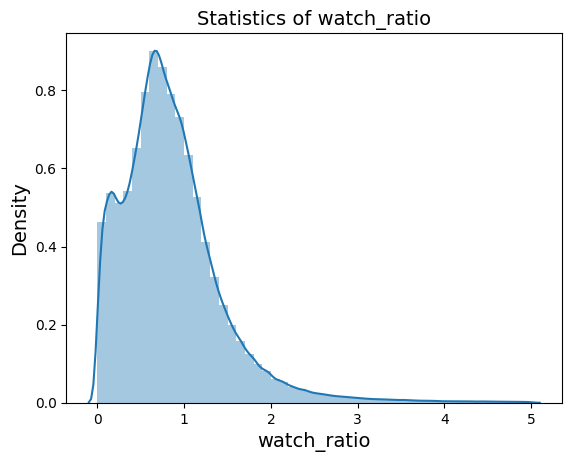

In [25]:
small_watch_ratio = df.watch_ratio[df.watch_ratio <= 5]
print(small_watch_ratio.describe())
visual_continue(small_watch_ratio)

### Distribution of video duration in the big matrix (in millisecond)

count    1.253081e+07
mean     1.462157e+04
std      1.983474e+04
min      1.400000e+02
25%      7.434000e+03
50%      9.636000e+03
75%      1.217900e+04
max      3.150720e+05
Name: video_duration, dtype: float64


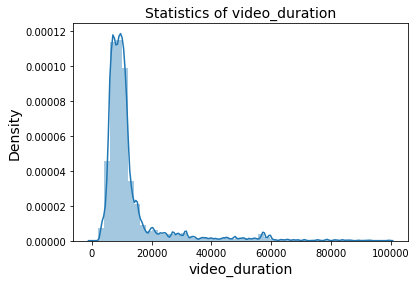

In [ ]:
big_video_duration = big_matrix.video_duration
print(big_video_duration.describe())
# visual_continue(big_video_duration)
visual_continue(big_video_duration[big_video_duration < 100000])

### Distribution of video duration in the small matrix (in millisecond)

count    1.894006e+06
mean     1.451370e+04
std      2.164899e+04
min      3.088000e+03
25%      7.534000e+03
50%      9.579000e+03
75%      1.183400e+04
max      3.150720e+05
Name: video_duration, dtype: float64


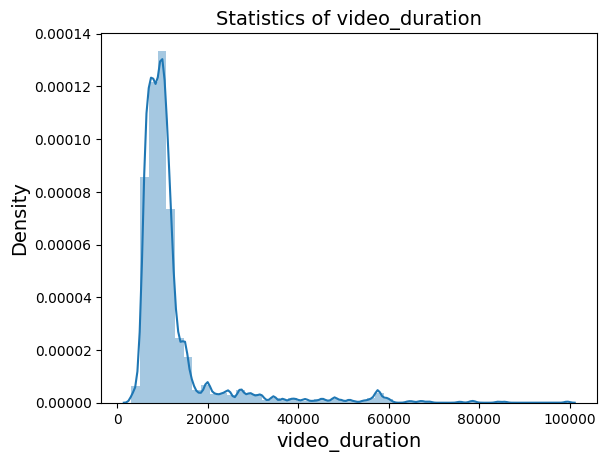

In [26]:
small_video_duration = df.video_duration
print(small_video_duration.describe())
# visual_continue(small_video_duration)
visual_continue(small_video_duration[small_video_duration < 100000])

### Distribution of each user's total play times in the big matrix

               date
count   7176.000000
mean    1746.210424
std      991.832222
min      100.000000
25%      883.000000
50%     1846.500000
75%     2461.000000
max    16015.000000


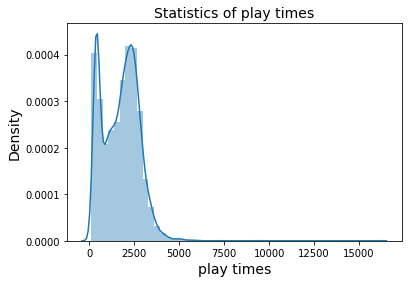

In [ ]:
big_play_time = big_matrix.groupby('user_id').agg({"date":len})
big_play_time.name = "play times"
print(big_play_time.describe())
visual_continue(big_play_time)

### Distribution of each user's total play times in the small matrix

              date
count  1411.000000
mean   3314.365698
std       6.984852
min    3295.000000
25%    3309.000000
50%    3315.000000
75%    3320.000000
max    3327.000000


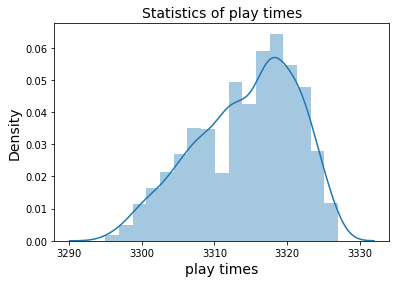

In [ ]:
small_play_time = small_matrix.groupby('user_id').agg({"date":len})
small_play_time.name = "play times"
print(small_play_time.describe())
visual_continue(small_play_time)

### Distribution of each user's daily play times in the big matrix

count    188322.000000
mean         66.539257
std          78.752240
min           1.000000
25%          19.000000
50%          42.000000
75%          83.000000
max        3268.000000
Name: play times, dtype: float64


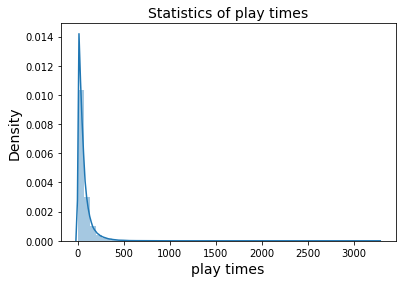

In [ ]:
big_daily_play_time = big_matrix.groupby(['user_id', 'date']).size()
big_daily_play_time.name = "play times"
print(big_daily_play_time.describe())
visual_continue(big_daily_play_time)

### Distribution of each user's daily play times in the small matrix

count    86671.000000
mean        51.857922
std         32.608372
min          1.000000
25%         28.000000
50%         47.000000
75%         70.000000
max        402.000000
Name: play times, dtype: float64


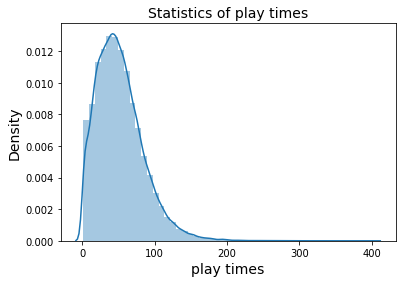

In [ ]:
small_daily_play_time = small_matrix.groupby(['user_id', 'date']).size()
small_daily_play_time.name = "play times"
print(small_daily_play_time.describe())
visual_continue(small_daily_play_time)

In [27]:
1100*1800

1980000

В результате проведения EDA анализа было решено использовать данные из small_matrix, предварительно их подготовить:
1) Удалить взаимодействия без поля 'timestamp'. Таких объектов оказалось $\approx 4\%$,
2) Выбрать из матрицы случайно с зафиксированным сидом подмножество юзеров - 1100 и айтемов - 1800, тогда общее число взаимодействий будет не больше 1.98 млн
3) Отсортроавть взаимодействия по столбцу 'timestamp' и отложить в обучающую выьорку 70% первых объектов, в валидационную - 15% следующих и в тестовую - последние 15%. Это необходимо, чтобы
4) Оставить в валидационной и тестовой выборке только тех юзеров и айтемы, которые были в обучающей. Так как реализуемые рекомендательные модели плохо работают в ситуации колдстарта - избавимся от такого сценария.

Таким образом получен даатсет, содержащий

# Модели

In [1]:
!unzip /content/KuaiRec_First_Three_Models.zip

Archive:  /content/KuaiRec_First_Three_Models.zip
   creating: KuaiRec_First_Three_Models/
  inflating: KuaiRec_First_Three_Models/smoke_test.py  
  inflating: KuaiRec_First_Three_Models/README.md  
   creating: KuaiRec_First_Three_Models/models/
  inflating: KuaiRec_First_Three_Models/models/ials.py  
  inflating: KuaiRec_First_Three_Models/models/ease.py  
  inflating: KuaiRec_First_Three_Models/models/user_cf.py  
  inflating: KuaiRec_First_Three_Models/models/common.py  
  inflating: KuaiRec_First_Three_Models/models/__init__.py  
   creating: KuaiRec_First_Three_Models/models/__pycache__/
  inflating: KuaiRec_First_Three_Models/models/__pycache__/__init__.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/user_cf.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/common.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/ials.cpython-313.pyc  
  inflating: KuaiRec_First_Three_Models/models/__pycache__/eas